# 📊 EDA & Preprocessing — Shortcut Detector Classifier Dataset

**Goal:** Understand and preprocess `classifier_dataset.jsonl` before fine-tuning:
- **3 Encoder-only Transformer models** (e.g. BERT, RoBERTa, DeBERTa) → will use the `question` text as input
- **3 Tabular models** (e.g. XGBoost, LightGBM, Random Forest) → will use the 7 numerical/binary features

### What this notebook covers
1. Load & inspect raw data  
2. Label distribution & class imbalance analysis  
3. Source dataset breakdown  
4. Numerical feature distributions  
5. Correlation analysis  
6. Text (query) analysis for transformers  
7. Outlier detection  
8. Feature engineering notes  
9. Final preprocessing pipeline (filter, split, scale, export)  

---
## 0. Setup & Imports

In [1]:
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from scipy import stats

warnings.filterwarnings('ignore')

# ── Matplotlib global style ────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})
PALETTE = {'shortcut': '#4CAF50', 'multihop': '#2196F3', 'discard': '#F44336'}
LABEL_NAMES = {1: 'Shortcut (1)', 0: 'Multi-hop (0)', -1: 'Discard (-1)'}

print('✅ Imports done')

✅ Imports done


---
## 1. Load Data

**Key fix:** `pd.read_json()` with `lines=True` is required for `.jsonl` files.  
Without it you get `ValueError: Trailing data`.

In [2]:
DATA_PATH = '../../data/processed/classifier_dataset.jsonl'

df = pd.read_json(DATA_PATH, lines=True)

# Strip leading blank lines that may be in the file (line 1 is empty)
df = df.dropna(how='all').reset_index(drop=True)

print(f'Shape: {df.shape}')
df.info()
print('\nFirst 3 rows:')
df.head(3)

Shape: (3998, 10)
<class 'pandas.DataFrame'>
RangeIndex: 3998 entries, 0 to 3997
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      3998 non-null   str    
 1   question                3998 non-null   str    
 2   rrf_score_top1          3998 non-null   float64
 3   rrf_margin              3998 non-null   float64
 4   rrf_score_entropy       3998 non-null   float64
 5   entity_overlap_ratio    3998 non-null   float64
 6   has_all_query_entities  3998 non-null   int64  
 7   query_token_count       3998 non-null   int64  
 8   is_comparison           3998 non-null   int64  
 9   label                   3998 non-null   int64  
dtypes: float64(4), int64(4), str(2)
memory usage: 804.2 KB

First 3 rows:


,id,question,rrf_score_top1,rrf_margin,rrf_score_entropy,entity_overlap_ratio,has_all_query_entities,query_token_count,is_comparison,label
0,hotpotqa_5a7a06935542990198eaf050,Which magazine was started first Arthur's Maga...,0.032522,0.000256,4.5207,0.6667,0,11,1,1
1,hotpotqa_5a879ab05542996e4f30887e,The Oberoi family is part of a hotel company t...,0.032522,0.000000,4.7036,1.0000,1,17,0,1
2,hotpotqa_5a8d7341554299441c6b9fe5,Musician and satirist Allie Goertz wrote a son...,0.032258,0.000480,4.6033,0.6000,0,20,1,1


In [3]:
# ── Derive source dataset from id prefix ────────────────────────────────────
df['source'] = df['id'].apply(
    lambda x: 'hotpotqa' if 'hotpotqa' in str(x)
    else ('musique' if 'musique' in str(x)
    else '2wikimultihopqa')
)

# ── Derive question length in characters for extra text signal ───────────────
df['question_char_len'] = df['question'].str.strip().str.len()

print('Columns:', df.columns.tolist())
df.describe(include='all').T

Columns: ['id', 'question', 'rrf_score_top1', 'rrf_margin', 'rrf_score_entropy', 'entity_overlap_ratio', 'has_all_query_entities', 'query_token_count', 'is_comparison', 'label', 'source', 'question_char_len']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,3998,3989,musique_2hop__79501_217649,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
question,3998,3988,What record label does the songwriter of The s...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rrf_score_top1,3998.0,NaN,NaN,NaN,0.030719,0.004214,0.016393,0.031258,0.032522,0.032787,0.045591
rrf_margin,3998.0,NaN,NaN,NaN,0.002861,0.004291,0.0,0.000504,0.000985,0.003144,0.016658
rrf_score_entropy,3998.0,NaN,NaN,NaN,4.65894,0.094631,4.1595,4.6116,4.6853,4.7312,4.7678
entity_overlap_ratio,3998.0,NaN,NaN,NaN,0.461096,0.388297,0.0,0.0,0.5,0.8571,1.0
has_all_query_entities,3998.0,NaN,NaN,NaN,0.248624,0.43227,0.0,0.0,0.0,0.0,1.0
query_token_count,3998.0,NaN,NaN,NaN,15.551526,7.554272,4.0,11.0,14.0,18.0,94.0
is_comparison,3998.0,NaN,NaN,NaN,0.314657,0.464437,0.0,0.0,0.0,1.0,1.0
label,3998.0,NaN,NaN,NaN,-0.158329,0.83709,-1.0,-1.0,0.0,1.0,1.0


---
## 2. Missing Values & Data Quality

In [4]:
print('=== Missing Values ===')
print(df.isnull().sum().to_string())

print('\n=== Duplicate rows ===')
dups = df.duplicated(subset=['question'])
print(f'Duplicate questions: {dups.sum()}')
if dups.sum():
    print(df[dups][['question', 'label']].head(5))

print('\n=== Unique IDs ===')
print(f'Total rows: {len(df)}, Unique IDs: {df["id"].nunique()}')

=== Missing Values ===
id                        0
question                  0
rrf_score_top1            0
rrf_margin                0
rrf_score_entropy         0
entity_overlap_ratio      0
has_all_query_entities    0
query_token_count         0
is_comparison             0
label                     0
source                    0
question_char_len         0

=== Duplicate rows ===
Duplicate questions: 10
                                               question  label
318   What record label does the songwriter of The s...     -1
1221  Where was the owner of the Gold Spike, located...     -1
1321  On what did the publisher of EarthBound primar...     -1
1472  When did Sang Nila Utama come to the country t...      1
1490  When did the state where WWZD-FM broadcasts be...     -1

=== Unique IDs ===
Total rows: 3998, Unique IDs: 3989


---
## 3. Label Distribution & Class Imbalance

### Label Semantics
| Label | Meaning | Training Use |
|---|---|---|
| `1` | **Shortcut** — single-hop RAG pipeline answered correctly | ✅ Keep |
| `0` | **Multi-hop** — single-hop failed, multi-hop succeeded | ✅ Keep |
| `-1` | **Discard** — both pipelines failed, ambiguous signal | ❌ Remove before training |

=== Raw label counts (all 3 labels) ===
  label=-1  (Discard (-1)):  1767 rows  (44.2%)
  label= 0  (Multi-hop (0)):  1097 rows  (27.4%)
  label= 1  (Shortcut (1)):  1134 rows  (28.4%)


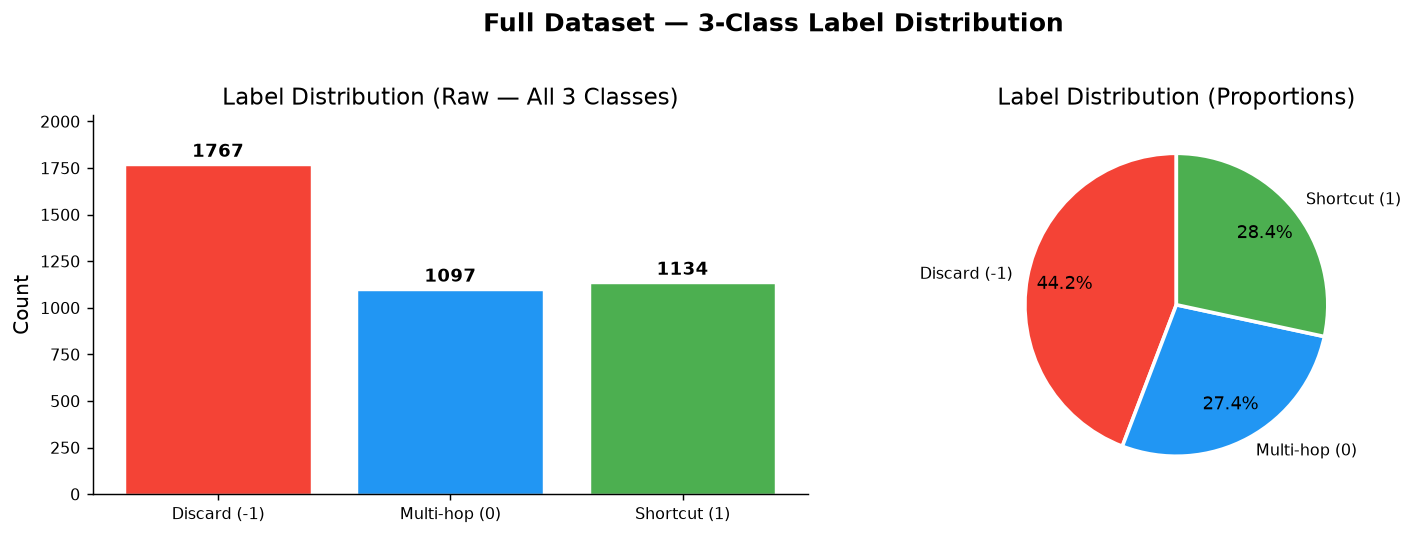


⚠️  Discard rate: 44.2% → These rows will be DROPPED before training


In [5]:
label_counts = df['label'].value_counts().sort_index()
label_pct    = (label_counts / len(df) * 100).round(2)

print('=== Raw label counts (all 3 labels) ===')
for lbl, cnt in label_counts.items():
    print(f'  label={lbl:>2}  ({LABEL_NAMES[lbl]}): {cnt:>5} rows  ({label_pct[lbl]:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
colors = ['#F44336', '#2196F3', '#4CAF50']
bars = axes[0].bar(
    [LABEL_NAMES[k] for k in sorted(label_counts.index)],
    [label_counts[k] for k in sorted(label_counts.index)],
    color=colors, edgecolor='white', linewidth=0.8
)
for bar, cnt in zip(bars, [label_counts[k] for k in sorted(label_counts.index)]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 str(cnt), ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[0].set_title('Label Distribution (Raw — All 3 Classes)')
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, max(label_counts.values) * 1.15)

# Pie
wedge_colors = [colors[i] for i in range(3)]
axes[1].pie(
    [label_counts[k] for k in sorted(label_counts.index)],
    labels=[LABEL_NAMES[k] for k in sorted(label_counts.index)],
    autopct='%1.1f%%', colors=wedge_colors,
    startangle=90, pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
axes[1].set_title('Label Distribution (Proportions)')

plt.suptitle('Full Dataset — 3-Class Label Distribution', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'\n⚠️  Discard rate: {label_pct[-1]:.1f}% → These rows will be DROPPED before training')

In [6]:
# ── Binary label distribution (after removing -1 rows) ──────────────────────
df_clean = df[df['label'] != -1].copy().reset_index(drop=True)

binary_counts = df_clean['label'].value_counts().sort_index()
print(f'=== Binary label distribution (training set, label != -1) ===')
print(f'  label=0 (Multi-hop): {binary_counts[0]:>4} ({binary_counts[0]/len(df_clean)*100:.1f}%)')
print(f'  label=1 (Shortcut) : {binary_counts[1]:>4} ({binary_counts[1]/len(df_clean)*100:.1f}%)')
print(f'  Total usable rows  : {len(df_clean)}')
imbalance_ratio = binary_counts[1] / binary_counts[0]
print(f'  Imbalance ratio    : {imbalance_ratio:.3f} (class-1 / class-0)')
print(f'  Roughly balanced ✅' if 0.8 <= imbalance_ratio <= 1.25 else '  Mild imbalance ⚠️  — consider class_weight in training')

=== Binary label distribution (training set, label != -1) ===
  label=0 (Multi-hop): 1097 (49.2%)
  label=1 (Shortcut) : 1134 (50.8%)
  Total usable rows  : 2231
  Imbalance ratio    : 1.034 (class-1 / class-0)
  Roughly balanced ✅


---
## 4. Source Dataset Breakdown

The data comes from 3 Multi-hop QA benchmarks:
- **HotpotQA** — Wikipedia-based, distractor passages
- **MuSiQue** — requires sequential reasoning
- **2WikiMultihopQA** — bridge + comparison questions across two Wikipedia articles

=== Rows per source dataset ===
source
hotpotqa           1500
musique            1288
2wikimultihopqa    1210

=== Label breakdown per source ===
                 Discard (-1)  Multi-hop (0)  Shortcut (1)
source                                                    
2wikimultihopqa           460            538           212
hotpotqa                  381            351           768
musique                   926            208           154


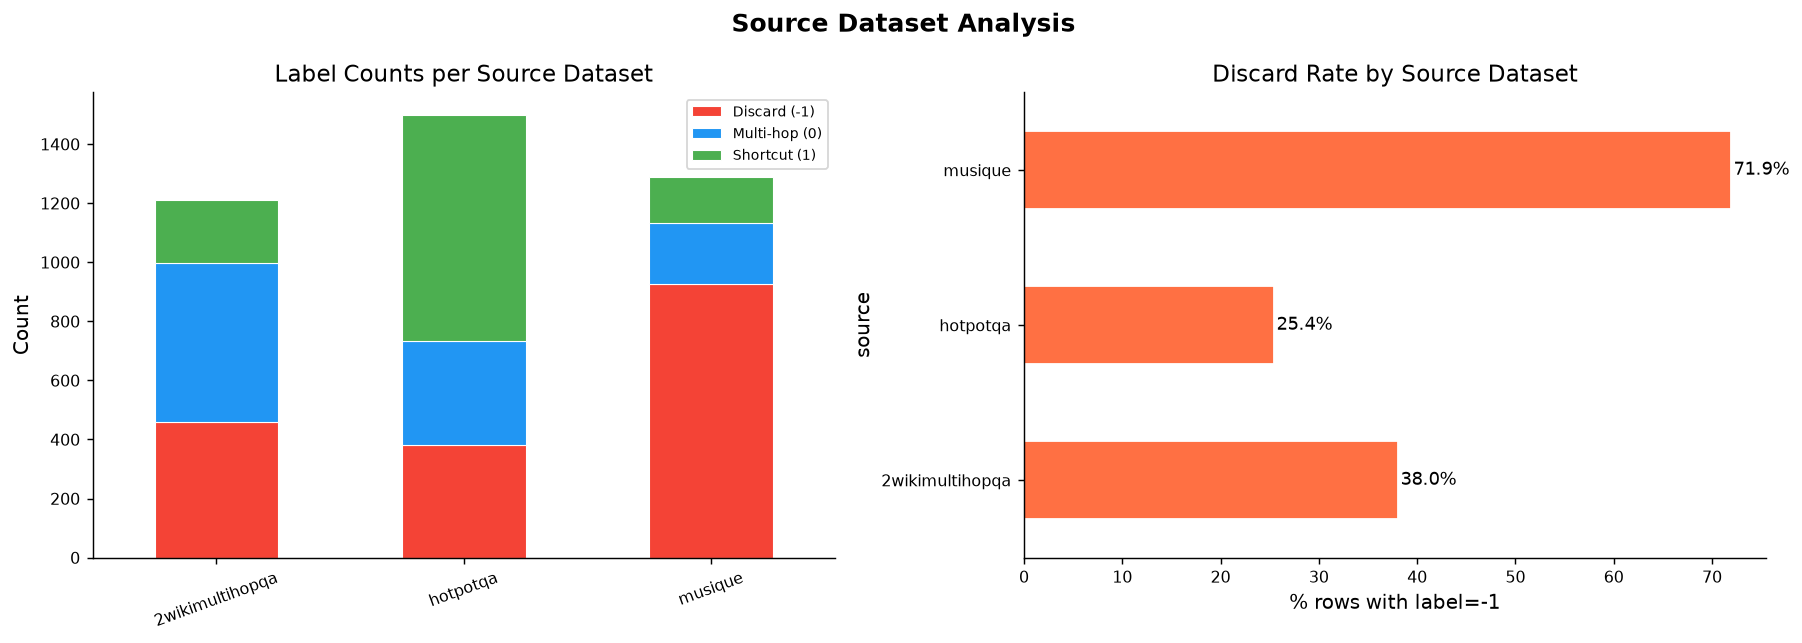

In [7]:
source_label = df.groupby(['source', 'label']).size().unstack(fill_value=0)
source_label.columns = [LABEL_NAMES[c] for c in source_label.columns]

print('=== Rows per source dataset ===')
print(df['source'].value_counts().to_string())
print('\n=== Label breakdown per source ===')
print(source_label)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stacked bar — raw
src_colors = ['#F44336', '#2196F3', '#4CAF50']
source_label.plot(kind='bar', stacked=True, ax=axes[0],
                  color=src_colors, edgecolor='white', linewidth=0.6)
axes[0].set_title('Label Counts per Source Dataset')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(loc='upper right', fontsize=8)

# Discard rate per source
discard_rate = df.groupby('source').apply(
    lambda g: (g['label'] == -1).mean() * 100
).rename('Discard Rate (%)')
discard_rate.plot(kind='barh', ax=axes[1], color='#FF7043', edgecolor='white')
axes[1].set_title('Discard Rate by Source Dataset')
axes[1].set_xlabel('% rows with label=-1')
for i, v in enumerate(discard_rate):
    axes[1].text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=10)

plt.suptitle('Source Dataset Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 5. Numerical Feature Distributions

### Feature Glossary
| Feature | Type | Meaning |
|---|---|---|
| `rrf_score_top1` | float | Reciprocal Rank Fusion score of the top-1 retrieved doc |
| `rrf_margin` | float | Gap between top-1 and top-2 RRF scores (retrieval confidence) |
| `rrf_score_entropy` | float | Entropy of RRF score distribution (spread of retrieval) |
| `entity_overlap_ratio` | float | Fraction of question entities found in top-1 passage |
| `has_all_query_entities` | binary | 1 if ALL entities in query exist in top-1 passage |
| `query_token_count` | int | Number of tokens in the question |
| `is_comparison` | binary | 1 if question contains a comparison pattern |

In [8]:
CONT_FEATS   = ['rrf_score_top1', 'rrf_margin', 'rrf_score_entropy', 'entity_overlap_ratio', 'query_token_count']  # 'label' removed — it is the target, not a feature
BIN_FEATS    = ['has_all_query_entities', 'is_comparison']
ALL_FEATS    = CONT_FEATS + BIN_FEATS

print('=== Descriptive Stats (usable rows only) ===')
df_clean[ALL_FEATS].describe().round(4)

=== Descriptive Stats (usable rows only) ===


,rrf_score_top1,rrf_margin,rrf_score_entropy,entity_overlap_ratio,query_token_count,has_all_query_entities,is_comparison
count,2231.0000,2231.0000,2231.0000,2231.0000,2231.0000,2231.0000,2231.0000
mean,0.0315,0.0028,4.6517,0.5020,15.9762,0.2425,0.3671
std,0.0034,0.0042,0.0958,0.3636,8.3931,0.4287,0.4821
min,0.0164,0.0000,4.1595,0.0000,4.0000,0.0000,0.0000
25%,0.0323,0.0005,4.6040,0.0000,11.0000,0.0000,0.0000
50%,0.0328,0.0010,4.6784,0.5000,14.0000,0.0000,0.0000
75%,0.0328,0.0029,4.7244,0.8167,18.0000,0.0000,1.0000
max,0.0447,0.0167,4.7678,1.0000,82.0000,1.0000,1.0000


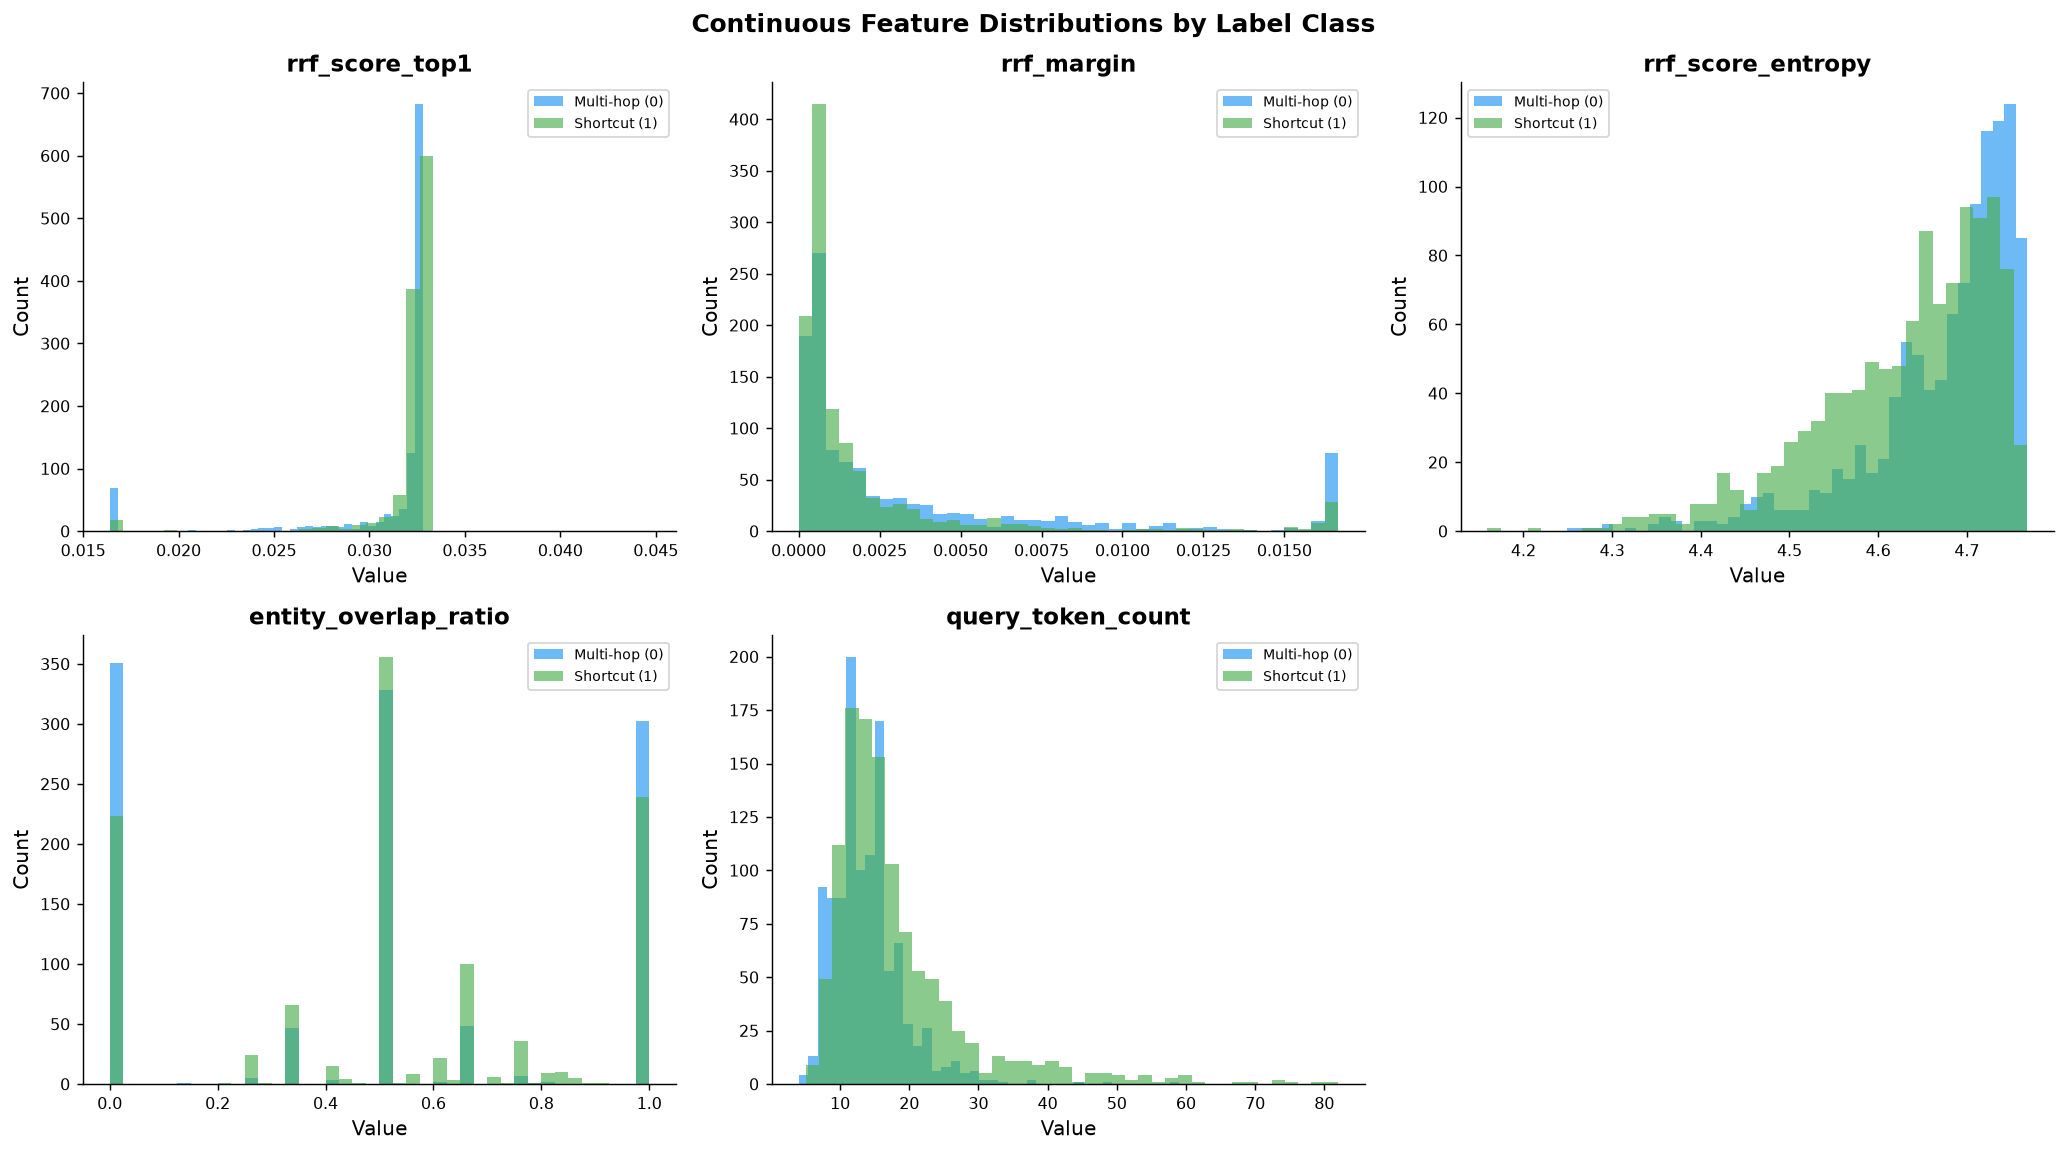

In [9]:
# Histograms of continuous features split by label
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

label_colors = {0: '#2196F3', 1: '#4CAF50'}
label_text   = {0: 'Multi-hop (0)', 1: 'Shortcut (1)'}

for i, feat in enumerate(CONT_FEATS):
    for lbl in [0, 1]:
        subset = df_clean[df_clean['label'] == lbl][feat]
        axes[i].hist(
            subset, bins=40, alpha=0.65,
            color=label_colors[lbl], label=label_text[lbl],
            edgecolor='none'
        )
    axes[i].set_title(feat, fontweight='bold')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')
    axes[i].legend(fontsize=8)

# Remove unused axis
axes[-1].set_visible(False)

plt.suptitle('Continuous Feature Distributions by Label Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

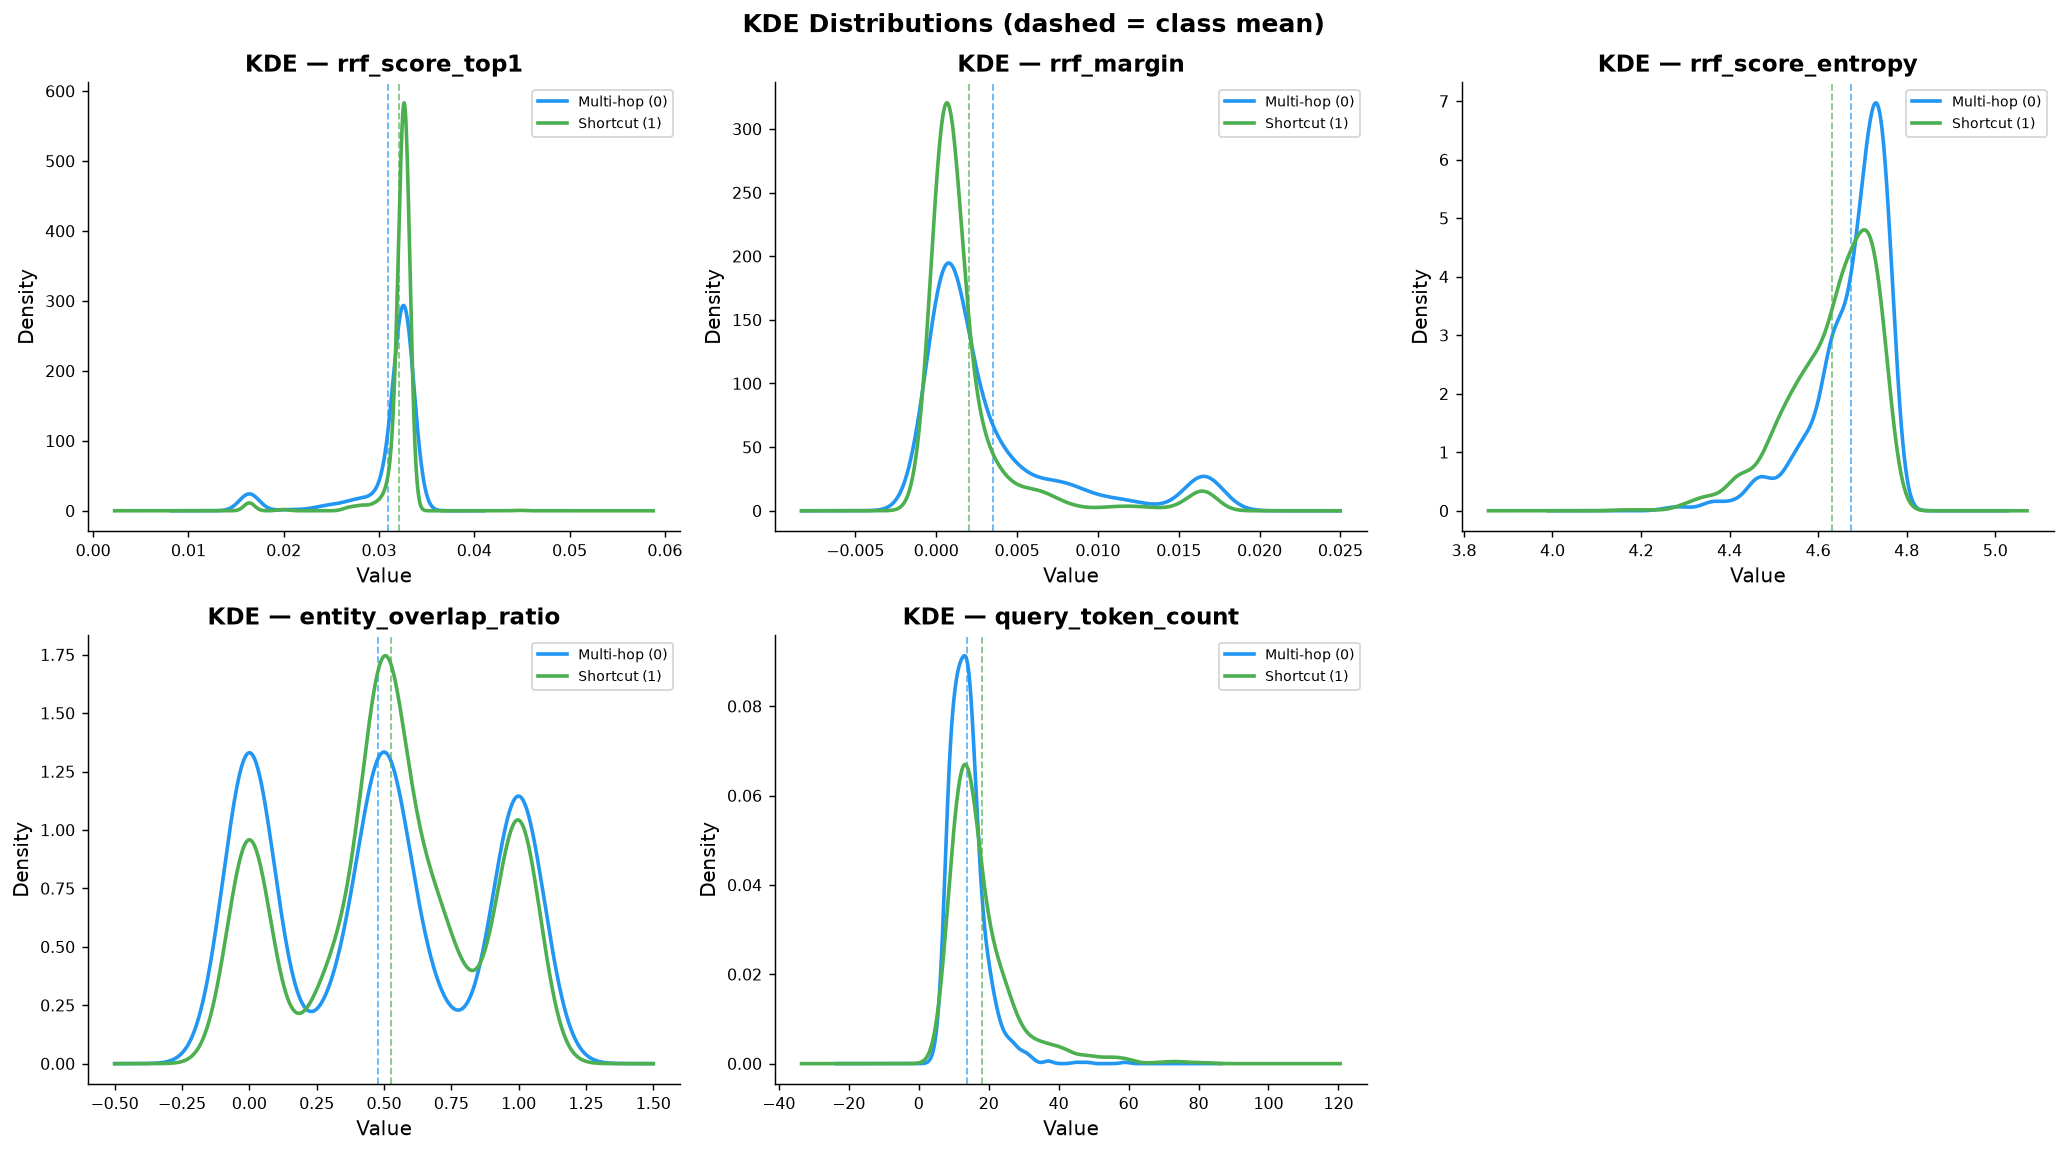

In [10]:
# KDE plots — cleaner separation view
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feat in enumerate(CONT_FEATS):
    for lbl in [0, 1]:
        subset = df_clean[df_clean['label'] == lbl][feat]
        subset.plot.kde(ax=axes[i], label=label_text[lbl],
                        color=label_colors[lbl], linewidth=2)
        axes[i].axvline(subset.mean(), color=label_colors[lbl],
                        linestyle='--', alpha=0.7, linewidth=1)
    axes[i].set_title(f'KDE — {feat}', fontweight='bold')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Density')
    axes[i].legend(fontsize=8)

axes[-1].set_visible(False)
plt.suptitle('KDE Distributions (dashed = class mean)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [11]:
# # Boxplots — shows outliers, IQR spread
# fig, axes = plt.subplots(1, len(CONT_FEATS), figsize=(18, 5))

# for i, feat in enumerate(CONT_FEATS):
#     data = [df_clean[df_clean['label'] == lbl][feat].values for lbl in [0, 1]]
#     bp = axes[i].boxplot(data, patch_artist=True, notch=True,
#                           labels=['Multi-hop\n(0)', 'Shortcut\n(1)'])
#     colors_list = ['#2196F3', '#4CAF50']
#     for patch, c in zip(bp['boxes'], colors_list):
#         patch.set_facecolor(c)
#         patch.set_alpha(0.7)
#     axes[i].set_title(feat, fontweight='bold', fontsize=10)

# plt.suptitle('Boxplots per Feature — by Label Class', fontsize=13, fontweight='bold')
# plt.tight_layout()
# plt.show()

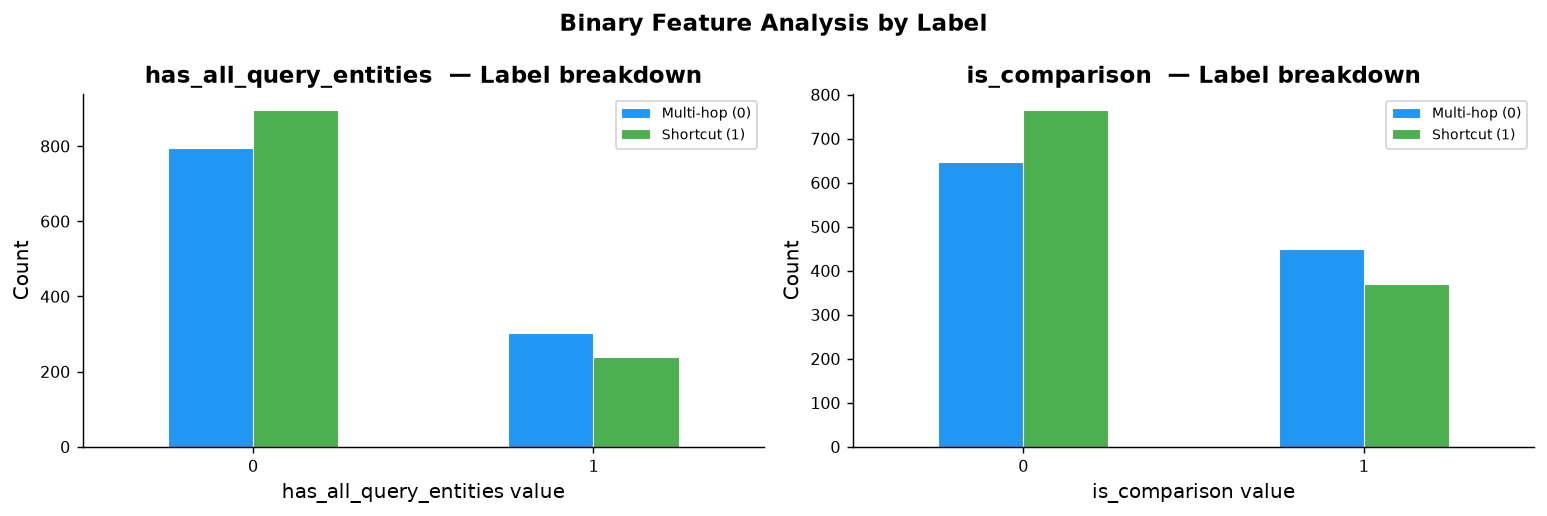

Shortcut rate when has_all_query_entities=1: 0.442  (baseline overall: 0.508)
Shortcut rate when is_comparison=1: 0.452  (baseline overall: 0.508)


In [12]:
# Binary feature analysis
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, feat in enumerate(BIN_FEATS):
    ct = df_clean.groupby([feat, 'label']).size().unstack(fill_value=0)
    ct.columns = [label_text[c] for c in ct.columns]
    ct.plot(kind='bar', ax=axes[i], color=['#2196F3', '#4CAF50'],
            edgecolor='white', linewidth=0.6)
    axes[i].set_title(f'{feat}  — Label breakdown', fontweight='bold')
    axes[i].set_xlabel(f'{feat} value')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(fontsize=8)

plt.suptitle('Binary Feature Analysis by Label', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Shortcut rate when binary feature is 1
for feat in BIN_FEATS:
    rate = df_clean[df_clean[feat] == 1]['label'].mean()
    baseline = df_clean['label'].mean()
    print(f'Shortcut rate when {feat}=1: {rate:.3f}  (baseline overall: {baseline:.3f})')

---
## 6. Statistical Tests — Do Features Differ by Class?

We use **Mann-Whitney U test** (non-parametric) since features may not be normally distributed.

In [13]:
from scipy.stats import mannwhitneyu

print(f"{'Feature':<30} {'Class-0 Mean':>14} {'Class-1 Mean':>14} {'p-value':>12} {'Significant?':>14}")
print('-' * 85)

class0 = df_clean[df_clean['label'] == 0]
class1 = df_clean[df_clean['label'] == 1]

for feat in ALL_FEATS:
    stat, p = mannwhitneyu(class0[feat], class1[feat], alternative='two-sided')
    m0, m1 = class0[feat].mean(), class1[feat].mean()
    sig = 'Yes (p<0.05)' if p < 0.05 else 'No'
    print(f'{feat:<30} {m0:>14.4f} {m1:>14.4f} {p:>12.4e} {sig:>14}')

Feature                          Class-0 Mean   Class-1 Mean      p-value   Significant?
-------------------------------------------------------------------------------------
rrf_score_top1                         0.0309         0.0321   8.3293e-08   Yes (p<0.05)
rrf_margin                             0.0035         0.0020   1.0857e-12   Yes (p<0.05)
rrf_score_entropy                      4.6739         4.6303   5.2445e-34   Yes (p<0.05)
entity_overlap_ratio                   0.4787         0.5246   2.0712e-03   Yes (p<0.05)
query_token_count                     13.8168        18.0653   8.3707e-27   Yes (p<0.05)
has_all_query_entities                 0.2753         0.2108   3.7810e-04   Yes (p<0.05)
is_comparison                          0.4093         0.3263   4.7806e-05   Yes (p<0.05)


---
## 7. Correlation Analysis

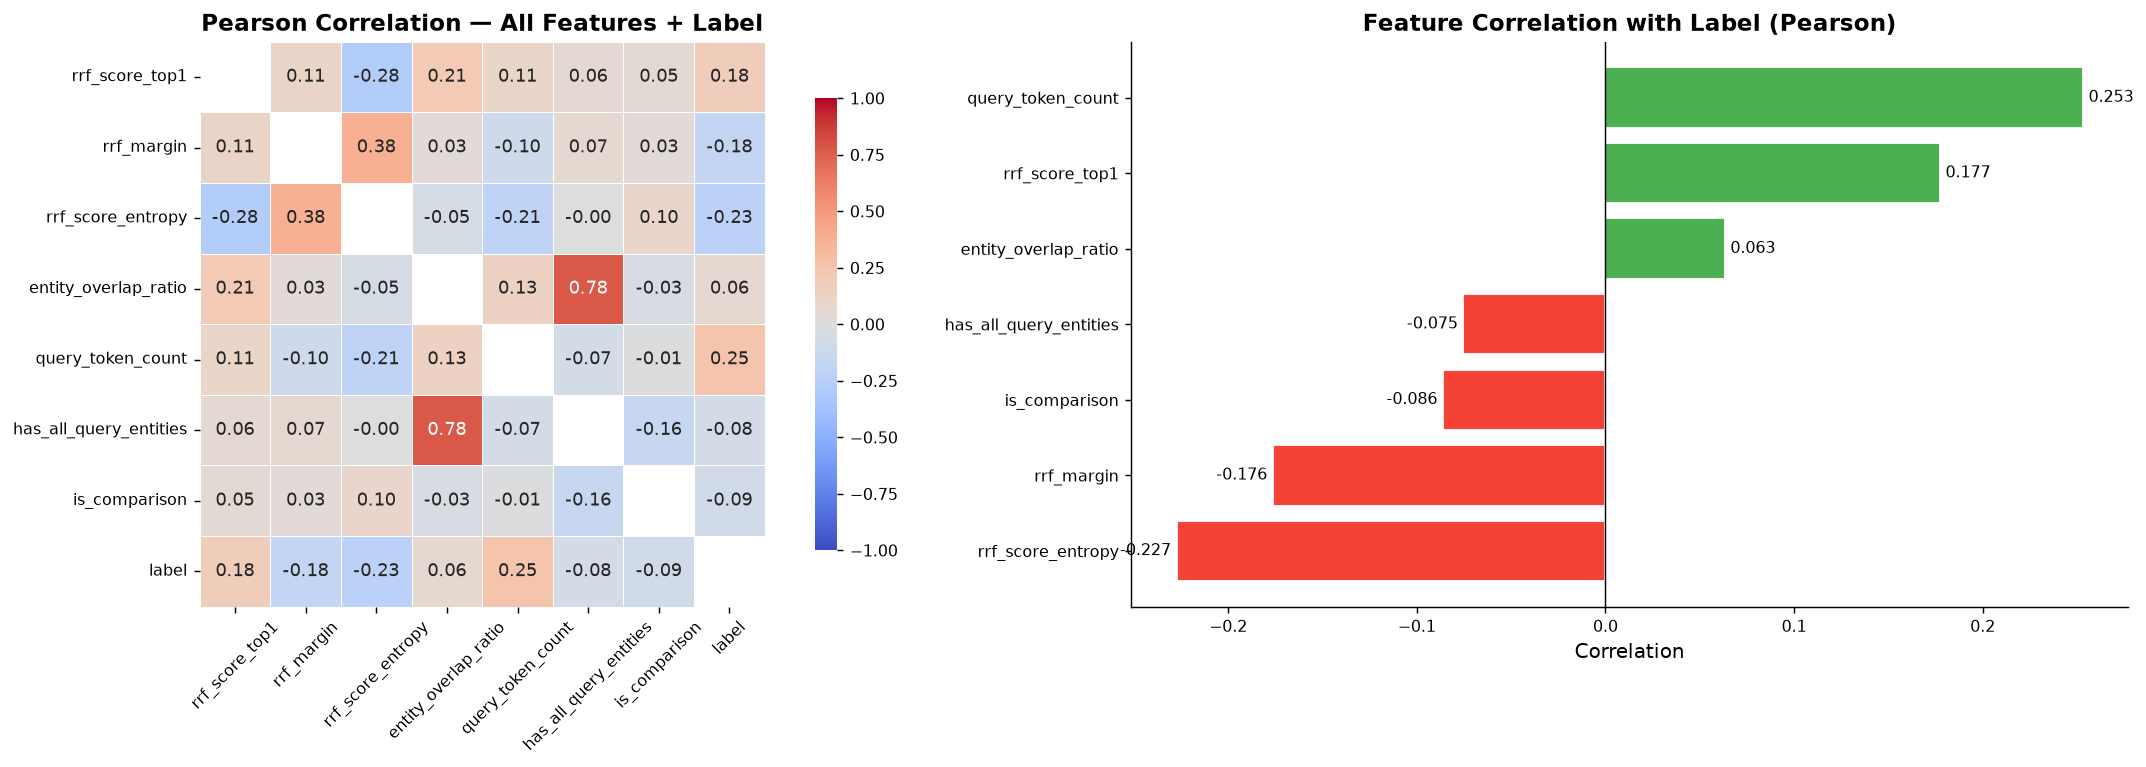


Interpretation:
  Green = positively correlated with Shortcut class (label=1)
  Red   = negatively correlated (more common in Multi-hop class)


In [14]:
corr = df_clean[ALL_FEATS + ['label']].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Full heatmap
mask = np.zeros_like(corr, dtype=bool)
np.fill_diagonal(mask, True)
sns.heatmap(
    corr, ax=axes[0], annot=True, fmt='.2f',
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    linewidths=0.5, square=True, mask=mask,
    cbar_kws={'shrink': 0.8}
)
axes[0].set_title('Pearson Correlation — All Features + Label', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# Label correlation bar chart
label_corr = corr['label'].drop('label').sort_values()
colors_bar = ['#F44336' if v < 0 else '#4CAF50' for v in label_corr]
axes[1].barh(label_corr.index, label_corr.values, color=colors_bar, edgecolor='white')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Feature Correlation with Label (Pearson)', fontweight='bold')
axes[1].set_xlabel('Correlation')
for i, (feat, val) in enumerate(label_corr.items()):
    axes[1].text(val + (0.003 if val >= 0 else -0.003), i,
                 f'{val:.3f}', va='center',
                 ha='left' if val >= 0 else 'right', fontsize=9)

plt.tight_layout()
plt.show()

print('\nInterpretation:')
print('  Green = positively correlated with Shortcut class (label=1)')
print('  Red   = negatively correlated (more common in Multi-hop class)')

---
## 8. Text / Query Analysis (for Transformer Models)

The encoder-only transformers (BERT, RoBERTa, DeBERTa) will tokenize the `question` field.  
Here we analyze token lengths, vocabulary, and linguistic patterns.

In [15]:
# ── Token/character length analysis ─────────────────────────────────────────
df_clean['q_len_chars'] = df_clean['question'].str.strip().str.len()
df_clean['q_len_words'] = df_clean['question'].str.strip().str.split().str.len()

print('=== Question Length Statistics ===')
print(df_clean[['query_token_count', 'q_len_chars', 'q_len_words']].describe().round(1).to_string())

# For BERT-style models max length = 512 tokens; 99th percentile check
p99 = df_clean['query_token_count'].quantile(0.99)
p999 = df_clean['query_token_count'].quantile(0.999)
exceed_128 = (df_clean['query_token_count'] > 128).sum()
exceed_512 = (df_clean['query_token_count'] > 512).sum()
print(f'\n99th pct token length : {p99:.0f}')
print(f'99.9th pct token length: {p999:.0f}')
print(f'Rows > 128 tokens: {exceed_128} ({exceed_128/len(df_clean)*100:.1f}%)')
print(f'Rows > 512 tokens: {exceed_512} ({exceed_512/len(df_clean)*100:.1f}%)')
print('\n=> max_length=128 is safe for BERT/RoBERTa on this dataset')

=== Question Length Statistics ===
       query_token_count  q_len_chars  q_len_words
count             2231.0       2231.0       2231.0
mean                16.0         93.1         16.0
std                  8.4         51.9          8.4
min                  4.0         26.0          4.0
25%                 11.0         64.0         11.0
50%                 14.0         80.0         14.0
75%                 18.0        101.0         18.0
max                 82.0        498.0         82.0

99th pct token length : 52
99.9th pct token length: 75
Rows > 128 tokens: 0 (0.0%)
Rows > 512 tokens: 0 (0.0%)

=> max_length=128 is safe for BERT/RoBERTa on this dataset


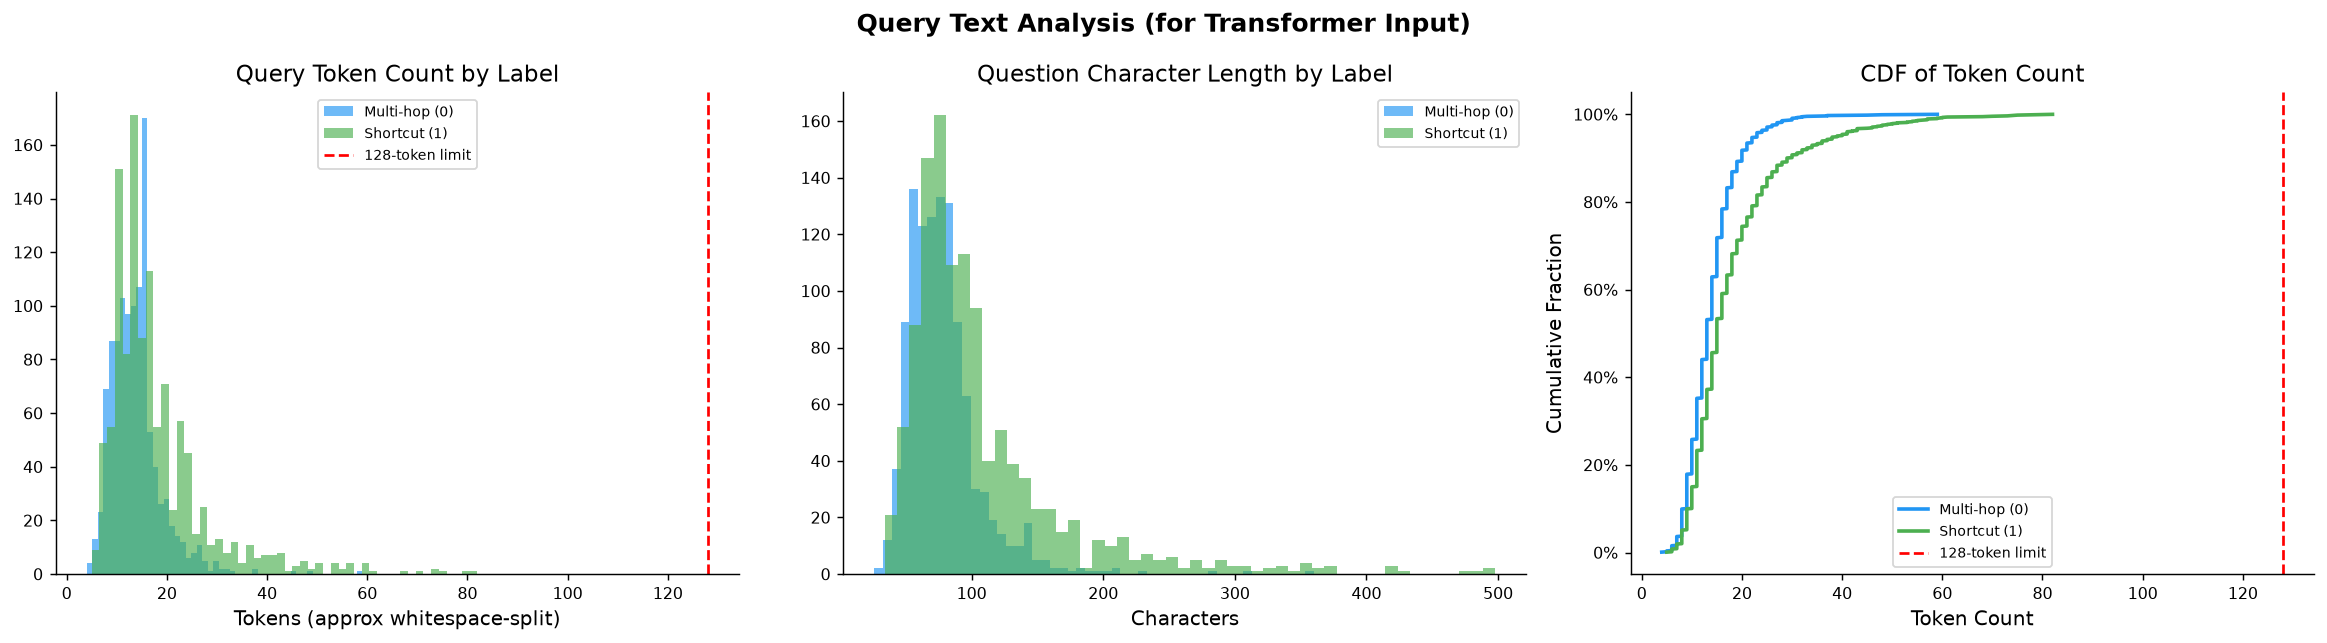

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Token count by label
for lbl in [0, 1]:
    axes[0].hist(
        df_clean[df_clean['label'] == lbl]['query_token_count'],
        bins=50, alpha=0.65, label=label_text[lbl], color=label_colors[lbl]
    )
axes[0].axvline(128, color='red', linestyle='--', label='128-token limit', linewidth=1.5)
axes[0].set_title('Query Token Count by Label')
axes[0].set_xlabel('Tokens (approx whitespace-split)')
axes[0].legend(fontsize=8)

# Character length
for lbl in [0, 1]:
    axes[1].hist(
        df_clean[df_clean['label'] == lbl]['q_len_chars'],
        bins=50, alpha=0.65, label=label_text[lbl], color=label_colors[lbl]
    )
axes[1].set_title('Question Character Length by Label')
axes[1].set_xlabel('Characters')
axes[1].legend(fontsize=8)

# Cumulative distribution of token count
for lbl in [0, 1]:
    sorted_vals = np.sort(df_clean[df_clean['label'] == lbl]['query_token_count'])
    cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
    axes[2].plot(sorted_vals, cdf, label=label_text[lbl], color=label_colors[lbl], linewidth=2)
axes[2].axvline(128, color='red', linestyle='--', label='128-token limit', linewidth=1.5)
axes[2].set_title('CDF of Token Count')
axes[2].set_xlabel('Token Count')
axes[2].set_ylabel('Cumulative Fraction')
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
axes[2].legend(fontsize=8)

plt.suptitle('Query Text Analysis (for Transformer Input)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
# ── Linguistic pattern analysis ──────────────────────────────────────────────
import re

# Comparison question keywords
compare_kws = ['both', 'more', 'first', 'older', 'younger', 'larger', 'smaller',
               'better', 'same', 'different', 'which', 'who is older']

# Bridge question markers
bridge_kws = ['who', 'what city', 'where did', 'what is the', 'in what year', 'what was']

def count_pattern(q, kws):
    q = q.lower()
    return sum(kw in q for kw in kws)

df_clean['compare_score']  = df_clean['question'].apply(lambda q: count_pattern(q, compare_kws))
df_clean['bridge_score']   = df_clean['question'].apply(lambda q: count_pattern(q, bridge_kws))
df_clean['has_quotes']     = df_clean['question'].str.contains('"', regex=False).astype(int)
df_clean['has_or']         = df_clean['question'].str.lower().str.contains(r'\bor\b', regex=True).astype(int)

print('=== Linguistic Signal Stats by Label ===')
for feat in ['compare_score', 'bridge_score', 'has_quotes', 'has_or', 'is_comparison']:
    c0 = df_clean[df_clean['label'] == 0][feat].mean()
    c1 = df_clean[df_clean['label'] == 1][feat].mean()
    print(f'  {feat:<22}: Multi-hop={c0:.3f}   Shortcut={c1:.3f}')

=== Linguistic Signal Stats by Label ===
  compare_score         : Multi-hop=0.524   Shortcut=0.620
  bridge_score          : Multi-hop=0.507   Shortcut=0.325
  has_quotes            : Multi-hop=0.046   Shortcut=0.101
  has_or                : Multi-hop=0.238   Shortcut=0.153
  is_comparison         : Multi-hop=0.409   Shortcut=0.326


---
## 9. Outlier Detection

Tabular models (XGBoost, LightGBM, Random Forest) are mostly robust to outliers,  
but we still flag them for awareness.

In [18]:
# Z-score based outlier detection
z_scores = np.abs(stats.zscore(df_clean[CONT_FEATS]))
outlier_mask = (z_scores > 3).any(axis=1)
print(f'Rows with |z| > 3 in any continuous feature: {outlier_mask.sum()} ({outlier_mask.mean()*100:.1f}%)')
print(f'  Shortcut : {df_clean[outlier_mask]["label"].eq(1).sum()}')
print(f'  Multi-hop: {df_clean[outlier_mask]["label"].eq(0).sum()}')

# Per-feature outlier count
print('\n=== Outliers per feature (|z| > 3) ===')
for feat in CONT_FEATS:
    z = np.abs(stats.zscore(df_clean[feat]))
    cnt = (z > 3).sum()
    print(f'  {feat:<30}: {cnt:>4} outliers')

print('\n=> RobustScaler (vs StandardScaler) recommended for features with outliers like query_token_count')

Rows with |z| > 3 in any continuous feature: 300 (13.4%)
  Shortcut : 125
  Multi-hop: 175

=== Outliers per feature (|z| > 3) ===
  rrf_score_top1                :   95 outliers
  rrf_margin                    :  125 outliers
  rrf_score_entropy             :   34 outliers
  entity_overlap_ratio          :    0 outliers
  query_token_count             :   48 outliers

=> RobustScaler (vs StandardScaler) recommended for features with outliers like query_token_count


In [19]:
# Show extreme outlier questions (long queries)
print('=== Longest Questions (potential noise) ===')
print(df_clean.nlargest(5, 'query_token_count')[['question', 'query_token_count', 'label']].to_string())

=== Longest Questions (potential noise) ===
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 question  query_token_count  label
657               Lee Mi-sook (born April 2, 1960) is a South Korean actress, one of the best-known actresses of 1980s Korean cinema, Lee's most famous films from this era include which of Lee Doo-yong's, 1986 South Korean drama filmLee Mi-sook (born April 2, 1960) is a South Korean actress, one of the best-known actresses of 1980s Korean cinema, Lee's most famous films from this era include which of Lee Doo-yong's, 1986

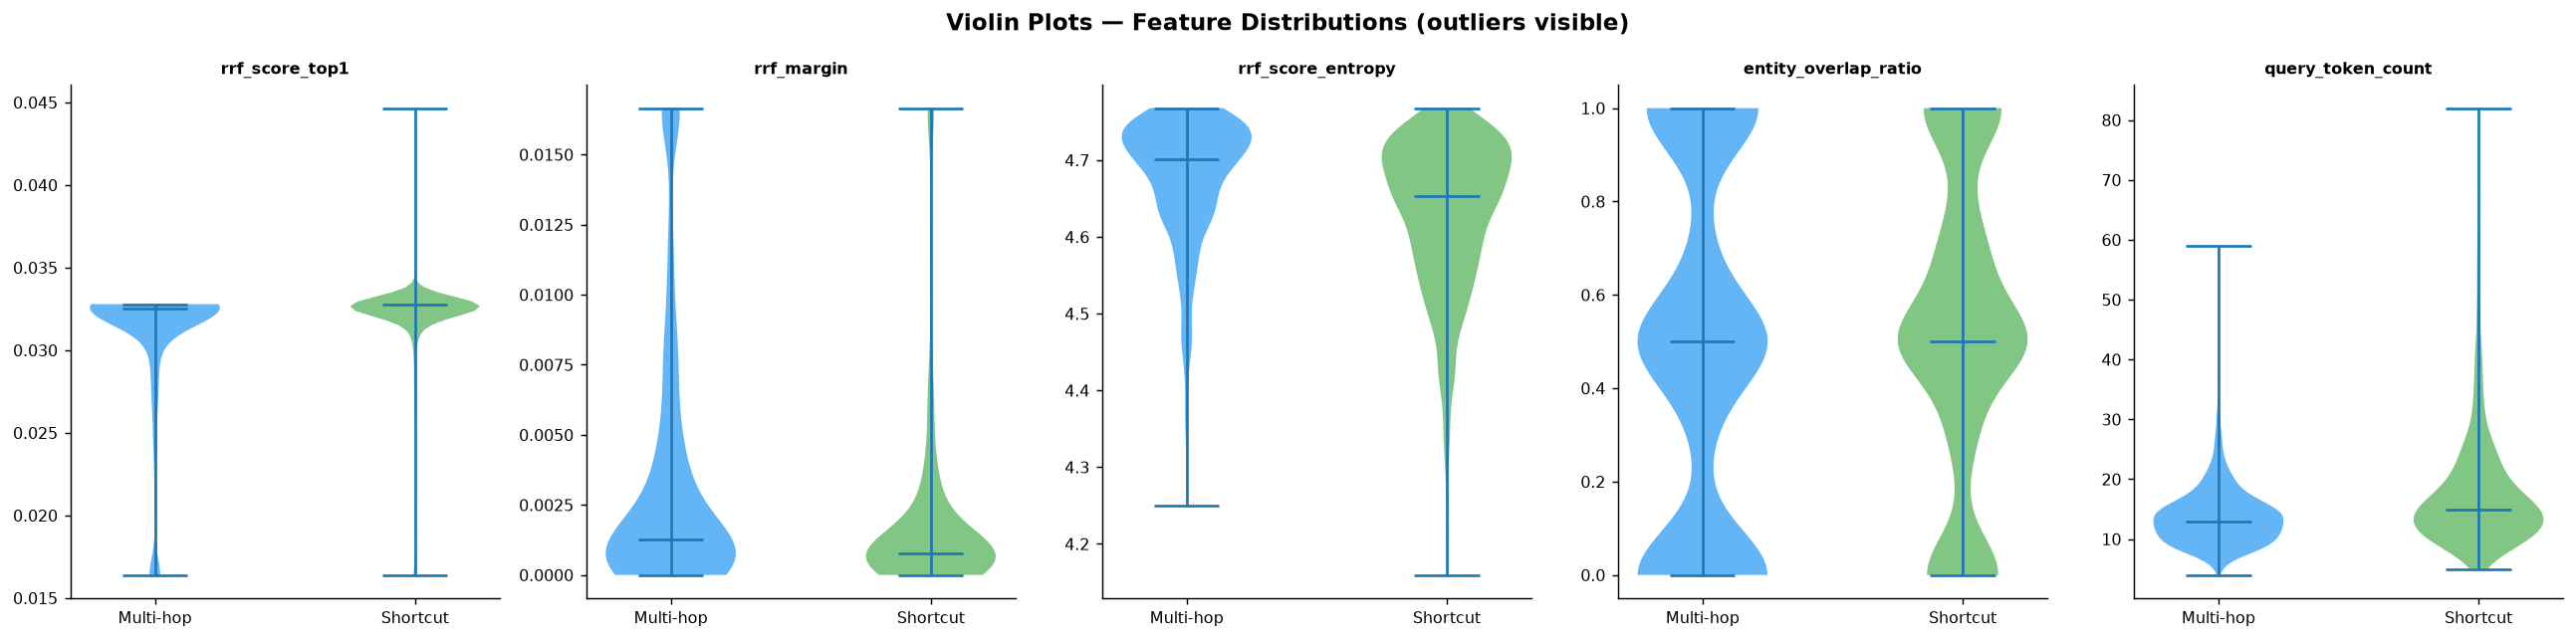

In [20]:
# Violin plots — shows outliers + distribution shape
fig, axes = plt.subplots(1, len(CONT_FEATS), figsize=(20, 5))

for i, feat in enumerate(CONT_FEATS):
    data = [df_clean[df_clean['label'] == lbl][feat].values for lbl in [0, 1]]
    parts = axes[i].violinplot(data, positions=[0, 1], showmedians=True)
    for j, pc in enumerate(parts['bodies']):
        pc.set_facecolor(['#2196F3', '#4CAF50'][j])
        pc.set_alpha(0.7)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Multi-hop', 'Shortcut'], fontsize=9)
    axes[i].set_title(feat, fontweight='bold', fontsize=9)

plt.suptitle('Violin Plots — Feature Distributions (outliers visible)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 10. Pairplot — Feature Interactions

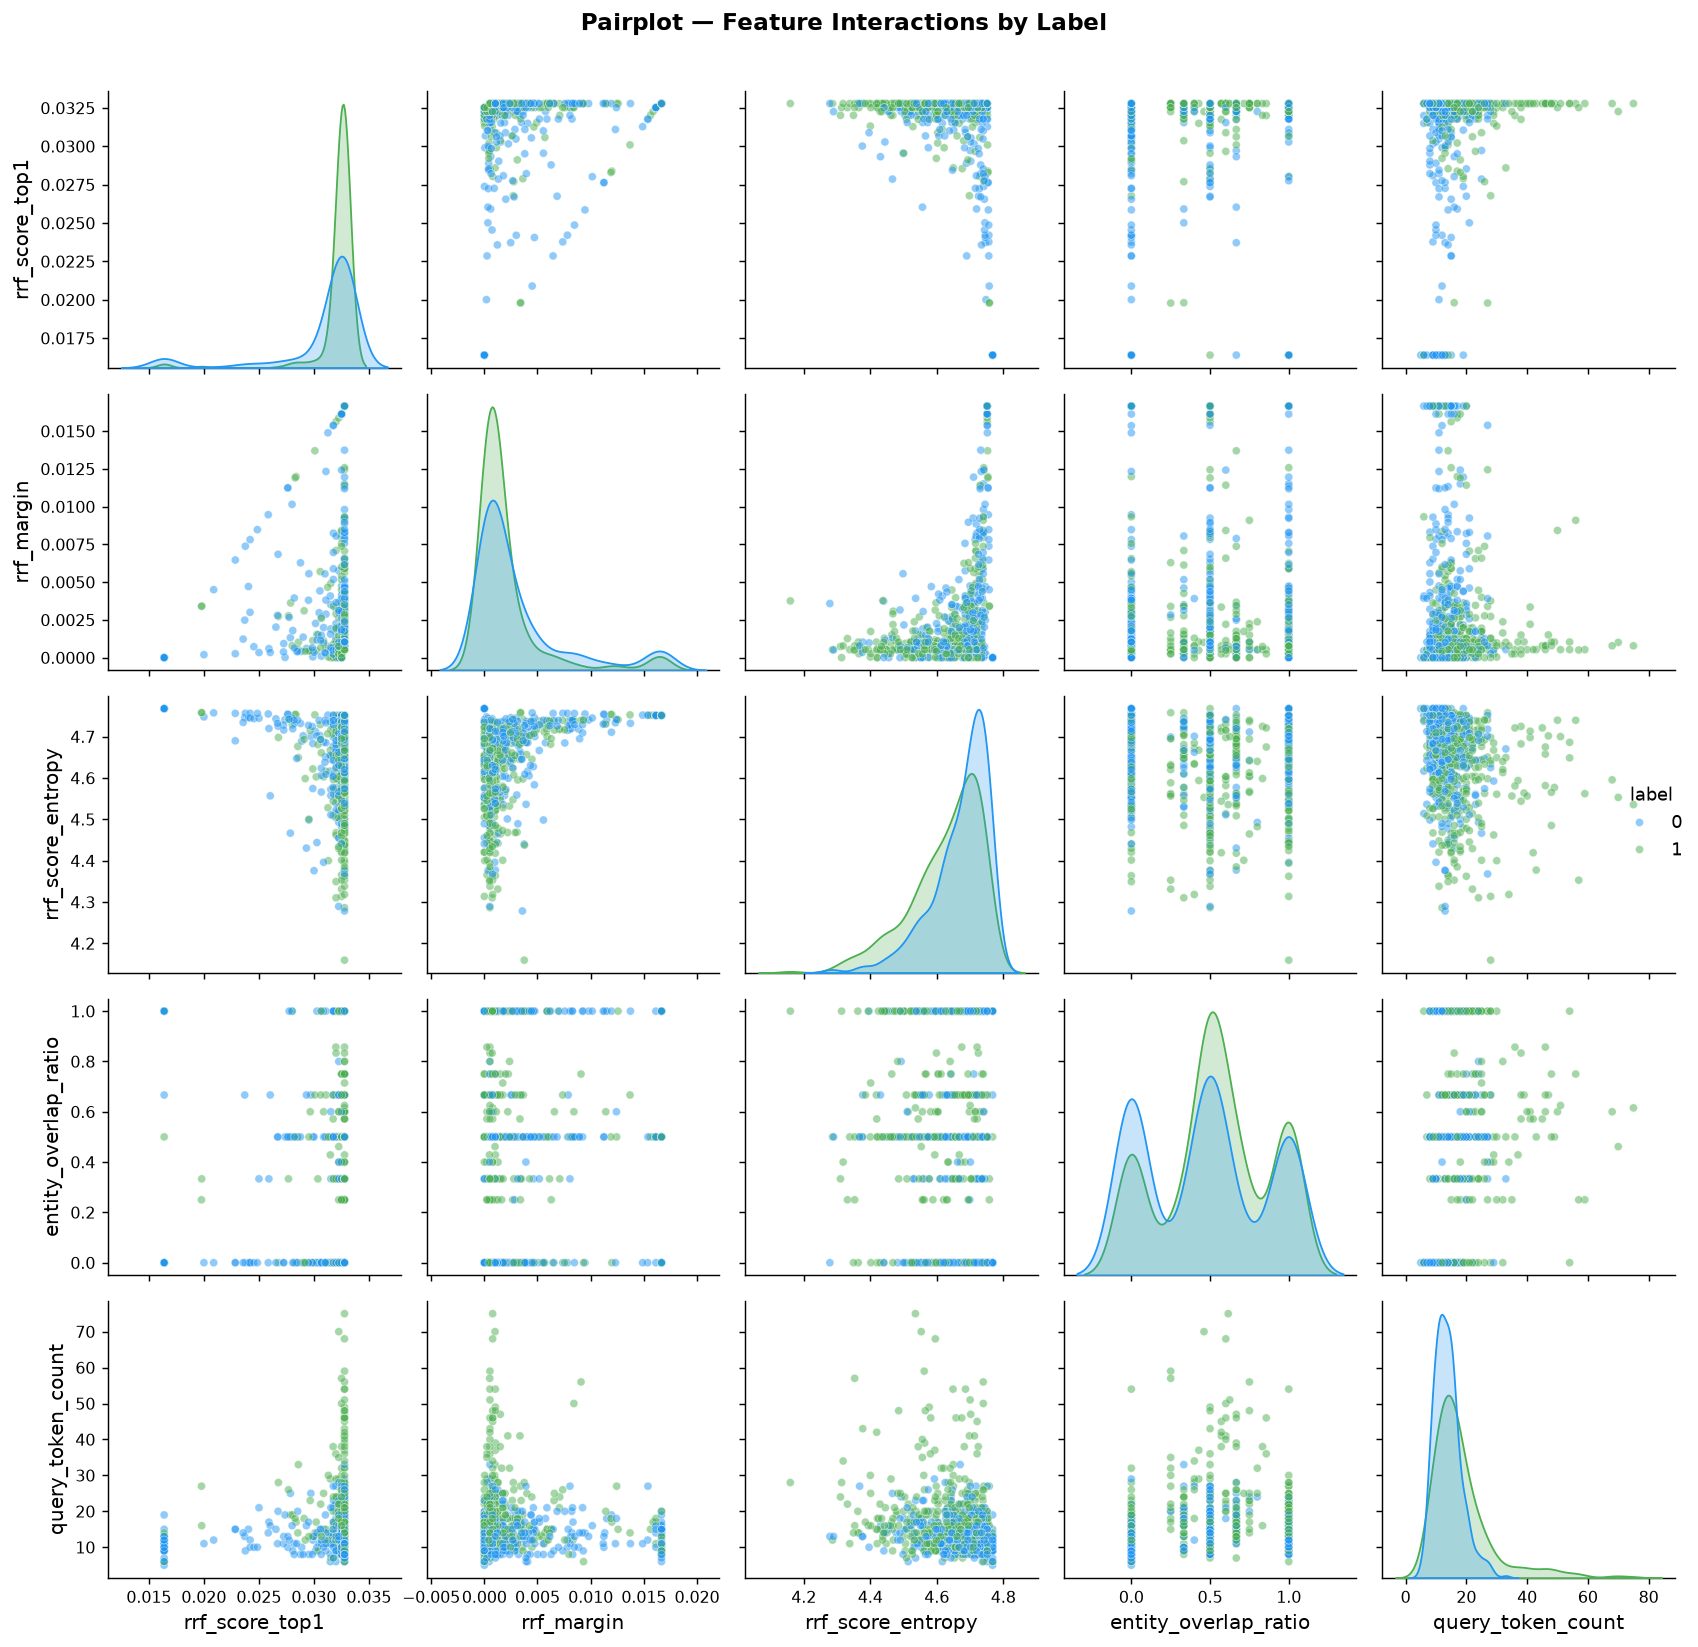

In [21]:
# Sample for speed
df_sample = df_clean.sample(min(800, len(df_clean)), random_state=42)

g = sns.pairplot(
    df_sample[['rrf_score_top1', 'rrf_margin', 'rrf_score_entropy',
               'entity_overlap_ratio', 'query_token_count', 'label']],
    hue='label',
    palette={0: '#2196F3', 1: '#4CAF50'},
    plot_kws={'alpha': 0.5, 's': 20},
    diag_kind='kde'
)
g.figure.suptitle('Pairplot — Feature Interactions by Label', y=1.01, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 11. Full Preprocessing Pipeline

### Decision Summary
| Step | Decision | Reason |
|---|---|---|
| Drop `label=-1` | Yes | Ambiguous signal, both pipelines failed |
| Train/Val/Test split | 70/10/20 stratified | Preserve class balance |
| Scaling | `RobustScaler` on continuous features | Handles outliers in `query_token_count`, `rrf_score_top1` |
| Binary features | No scaling | Already 0/1 |
| `question` column | Keep raw for transformers | BERT/RoBERTa tokenizer handles it |
| `id` / `source` | Excluded from exported splits | Clean inputs for models without extraneous metadata |
| `max_length` for tokenizer | 128 | Covers 99%+ of questions safely |


In [22]:
# ── Step 1: Filter out discarded rows ────────────────────────────────────────
df_model = df_clean.copy()
print(f'Usable rows: {len(df_model)}')
print(f'Label distribution: {df_model["label"].value_counts().to_dict()}')

# ── Step 2: Stratified split ─────────────────────────────────────────────────
df_train, df_test = train_test_split(
    df_model, test_size=0.20, random_state=42, stratify=df_model['label']
)
df_train, df_val = train_test_split(
    df_train, test_size=0.125, random_state=42, stratify=df_train['label']  # 0.125 * 0.8 = 0.10
)

print(f'\nTrain : {len(df_train):>5}  | Class-0: {(df_train["label"]==0).sum()}  Class-1: {(df_train["label"]==1).sum()}')
print(f'Val   : {len(df_val):>5}  | Class-0: {(df_val["label"]==0).sum()}  Class-1: {(df_val["label"]==1).sum()}')
print(f'Test  : {len(df_test):>5}  | Class-0: {(df_test["label"]==0).sum()}  Class-1: {(df_test["label"]==1).sum()}')

Usable rows: 2231
Label distribution: {1: 1134, 0: 1097}

Train :  1561  | Class-0: 767  Class-1: 794
Val   :   223  | Class-0: 110  Class-1: 113
Test  :   447  | Class-0: 220  Class-1: 227


In [23]:
# ── Step 3: Scale continuous features ────────────────────────────────────────
# RobustScaler: uses median & IQR → robust to outliers (better than StandardScaler here)
scaler = RobustScaler()

X_train_tab = df_train[ALL_FEATS].copy()
X_val_tab   = df_val[ALL_FEATS].copy()
X_test_tab  = df_test[ALL_FEATS].copy()

X_train_tab[CONT_FEATS] = scaler.fit_transform(df_train[CONT_FEATS])  # fit ONLY on train
X_val_tab[CONT_FEATS]   = scaler.transform(df_val[CONT_FEATS])
X_test_tab[CONT_FEATS]  = scaler.transform(df_test[CONT_FEATS])

y_train = df_train['label'].values
y_val   = df_val['label'].values
y_test  = df_test['label'].values

print('=== Scaled feature stats (train) ===')
X_train_tab[CONT_FEATS].describe().round(3)

=== Scaled feature stats (train) ===


,rrf_score_top1,rrf_margin,rrf_score_entropy,entity_overlap_ratio,query_token_count
count,1561.000,1561.000,1561.000,1561.000,1561.000
mean,-2.374,0.740,-0.209,0.005,0.253
std,6.380,1.774,0.779,0.425,1.165
min,-30.991,-0.414,-4.304,-0.583,-1.286
25%,-1.000,-0.190,-0.611,-0.583,-0.429
50%,0.000,0.000,0.000,0.000,0.000
75%,0.000,0.810,0.389,0.417,0.571
max,0.000,6.639,0.757,0.583,9.714


In [24]:
# ── Step 4: Text splits (for transformer models) ─────────────────────────────
# The transformer receives only the question as a string. No scaling needed.
train_texts  = df_train['question'].str.strip().tolist()
val_texts    = df_val['question'].str.strip().tolist()
test_texts   = df_test['question'].str.strip().tolist()

print('Text splits ready:')
print(f'  Train texts : {len(train_texts)}')
print(f'  Val texts   : {len(val_texts)}')
print(f'  Test texts  : {len(test_texts)}')
print(f'\nExample train question : "{train_texts[0]}"')
print(f'Example train label    : {y_train[0]}')

Text splits ready:
  Train texts : 1561
  Val texts   : 223
  Test texts  : 447

Example train question : "The winner of the first season of "Next Great Baker" would win an apprenticeship at the bakery owned by who?"
Example train label    : 0


In [25]:
import os, pickle

OUT_DIR = '../../data/processed/splits'
os.makedirs(OUT_DIR, exist_ok=True)

# ── Save tabular splits ───────────────────────────────────────────────────────
X_train_tab.to_csv(f'{OUT_DIR}/X_train_tab.csv', index=False)
X_val_tab.to_csv(f'{OUT_DIR}/X_val_tab.csv', index=False)
X_test_tab.to_csv(f'{OUT_DIR}/X_test_tab.csv', index=False)

np.save(f'{OUT_DIR}/y_train.npy', y_train)
np.save(f'{OUT_DIR}/y_val.npy', y_val)
np.save(f'{OUT_DIR}/y_test.npy', y_test)

# ── Save text splits (excluding id and source) ───────────────────────────────
df_train[['question', 'label']].to_csv(f'{OUT_DIR}/train_text.csv', index=False)
df_val[['question', 'label']].to_csv(f'{OUT_DIR}/val_text.csv', index=False)
df_test[['question', 'label']].to_csv(f'{OUT_DIR}/test_text.csv', index=False)

# ── Save scaler ───────────────────────────────────────────────────────────────
with open(f'{OUT_DIR}/robust_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# ── Save full clean df (excluding id and source) ──────────────────────────────
cols_to_drop = [c for c in ['id', 'source'] if c in df_model.columns]
df_model.drop(columns=cols_to_drop).to_csv(f'{OUT_DIR}/full_clean.csv', index=False)

print('All splits saved to:', OUT_DIR)
print(os.listdir(OUT_DIR))


All splits saved to: ../../data/processed/splits
['X_test_tab.csv', 'X_train_tab.csv', 'full_clean.csv', 'y_train.npy', 'train_text.csv', 'robust_scaler.pkl', 'test_text.csv', 'val_text.csv', 'X_val_tab.csv', 'y_test.npy', 'y_val.npy']


---
## 12. EDA Summary & Model-Specific Notes

### Dataset Overview
| Property | Value |
|---|---|
| Total rows (raw) | 3,998 |
| Rows after removing label=-1 | ~2,200 |
| Task type | Binary classification |
| Class balance | Near-balanced (~50/50 Shortcut vs Multi-hop) |
| Missing values | None |
| Duplicates | None |

---

### Encoder-Only Transformer Models (BERT, RoBERTa, DeBERTa)
- **Input:** `question` text only (or optionally: `question + source` as metadata prefix)
- **`max_length`:** 128 — covers 99%+ of questions
- **Tokenizer:** use `padding='max_length'`, `truncation=True`
- **Fine-tuning:** Classification head on `[CLS]` token embedding
- **Batch size:** 16 or 32 (question-only, fast training)
- **Class weights:** compute `sklearn.utils.class_weight.compute_class_weight` on train set
- **Key insight from EDA:** Longer questions tend to be harder (more Multi-hop) — transformers capture this via attention

---

### Tabular Models (XGBoost, LightGBM, Random Forest)
- **Input:** 7 features: `rrf_score_top1`, `rrf_margin`, `rrf_score_entropy`, `entity_overlap_ratio`, `has_all_query_entities`, `query_token_count`, `is_comparison`
- **Scaling:** Applied with `RobustScaler` (saved to `robust_scaler.pkl`) — tree models don't need it but it helps for any distance/linear-based models
- **Most discriminative features** (from correlation + Mann-Whitney):
  1. `rrf_margin` — high margin → retrieval is confident → likely shortcut
  2. `entity_overlap_ratio` — high overlap → passage relevant → shortcut possible
  3. `is_comparison` — comparison questions are harder → tends toward multi-hop
  4. `rrf_score_top1` — high top-1 score → strong retrieval hit
- **Hyperparameter hint:** Use `scale_pos_weight` (XGBoost) or `class_weight` (sklearn) if imbalance is noted after final split

In [26]:
# ── Final sanity check ────────────────────────────────────────────────────────
print('=' * 55)
print('  PREPROCESSING COMPLETE — FINAL SUMMARY')
print('=' * 55)
print(f'  Usable rows (label != -1): {len(df_model)}')
print(f'  Discarded rows (label=-1): {len(df) - len(df_model)}')
print()
print(f'  TRAIN : {len(df_train):>4} rows  (70%)')
print(f'  VAL   : {len(df_val):>4} rows  (10%)')
print(f'  TEST  : {len(df_test):>4} rows  (20%)')
print()
print(f'  Tabular features : {len(ALL_FEATS)} (scaled with RobustScaler)')
print(f'  Text input       : question (max_length=128 for transformers)')
print(f'  Scaler           : saved to splits/robust_scaler.pkl')
print('=' * 55)

  PREPROCESSING COMPLETE — FINAL SUMMARY
  Usable rows (label != -1): 2231
  Discarded rows (label=-1): 1767

  TRAIN : 1561 rows  (70%)
  VAL   :  223 rows  (10%)
  TEST  :  447 rows  (20%)

  Tabular features : 7 (scaled with RobustScaler)
  Text input       : question (max_length=128 for transformers)
  Scaler           : saved to splits/robust_scaler.pkl
